# SQL on FHIR Workshop

## Introduction

In this workshop, you will retrieve FHIR data, load it into Python,
select elements with [FHIRPath](https://www.hl7.org/fhir/fhirpath.html)
and [SQL on FHIR
ViewDefinitions](https://sql-on-fhir.org/ig/StructureDefinition-ViewDefinition.html),
and create tables for analysis. You do not need extensive Python
experience, but some familiarity will be helpful.

This is the workflow we will be using:

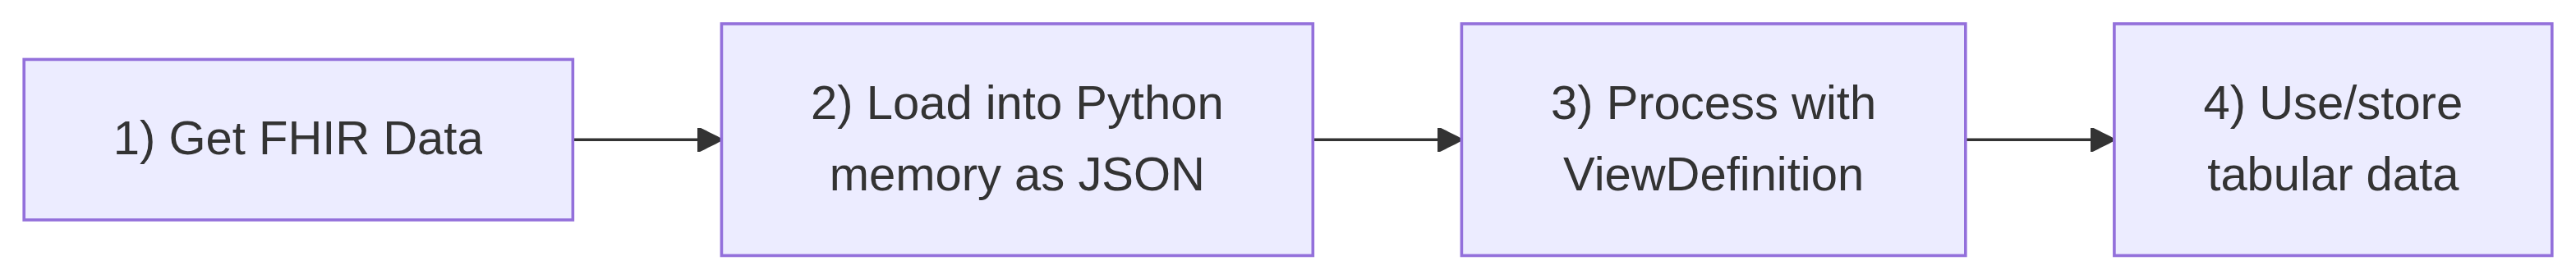

First, FHIR data is retrieved and loaded into memory from JSON. This
JSON is then processed using the SQL on FHIR ViewDefinition approach.
This produces a tabular representation of the FHIR data that can be used
downstream for analysis.

## Dependencies

The following Python libraries are needed for this exercise. Make sure
the cell below runs without errors before continuing.

In [2]:
%pip install httpx pandas IPython sqlonfhir rich

In [3]:
import json
from collections import Counter, defaultdict
from copy import deepcopy
from pathlib import Path
from urllib.parse import urljoin

import httpx
import pandas as pd
from IPython.display import JSON, display
import sqlonfhir

print("Ready to work with FHIR data.")

Ready to work with FHIR data.

## Get FHIR data

Outside this workshop, data might come from an EHR or another
FHIR-enabled source. However, for this workshop, we will use [synthetic
data](../modules/synthetic-data.qmd) on a public FHIR R4 test server. In
production, a FHIR server typically requires authentication and
authorization, but this is ignored as out of scope for this workshop.

There are two input formats to consider:

| Format | Typical source | What Python needs to load |
|------------------------|------------------------|------------------------|
| JSON | FHIR `read` or `search` | A `read` returns a resource; a `search` returns a [Bundle](https://hl7.org/fhir/R4/bundle.html) containing entries with resources. |
| NDJSON | FHIR Bulk Data `$export` or a downloaded dataset | Each nonempty line is a separate JSON resource. |

This notebook does not cover FHIR represented as XML, which is an
alternative to JSON but is not as widely used in modern software.

For more on the FHIR API interactions, see [Using the FHIR API to access
data](../modules/fhir-accessing-data.qmd).

### Example: patient blood pressure

Our initial goal is to **retrieve patients with blood pressure
readings**. There are three key questions that will guide the approach
we take in getting the relevant data from the FHIR server:

1.  Which resource types contain the information?
2.  Which terminology identifies the observations of interest?
3.  Where are the measurement values stored?

To determine which FHIR resource types are relevant, look at the [FHIR
R4 resource list](https://hl7.org/fhir/R4/resourcelist.html). Then look
at the elements in these resources to determine where measurement values
are stored, and if there is relevant terminology. A Large Language Model
(LLM) can be helpful for this in suggesting a starting point, but be
sure to verify its suggestions against the FHIR specification and, once
you retrieve it, your data.

For this example, [Patient](https://hl7.org/fhir/R4/patient.html) and
[Observation](https://hl7.org/fhir/R4/observation.html) are most
relevant: Patient is used to represent demographic information, while
Observation has the actual blood pressure measurement.

The [US Core blood pressure
profile](https://hl7.org/fhir/us/core/StructureDefinition-us-core-blood-pressure.html)
provides some additional guidance on how these values are likely
represented in FHIR in the United States:

| Meaning | [LOINC](http://loinc.org) code | Element containing the code |
|------------------------|------------------------|------------------------|
| Blood pressure panel | `85354-9` | `Observation.code.coding` |
| Systolic blood pressure | `8480-6` | `Observation.component.code.coding` |
| Diastolic blood pressure | `8462-4` | `Observation.component.code.coding` |

This gives us enough of a starting point to start trying to pull the
data.

### Constructing a FHIR search request

We will run the following search request against our FHIR server:

``` text
GET {base}/Patient
    ?_has:Observation:subject:code=http://loinc.org|85354-9
    &_revinclude=Observation:subject
```

The [`_has` parameter](https://hl7.org/fhir/R4/search.html#has) selects
Patients referenced by an Observation where the Observation has code
`85354-9` (the LOINC code identifying the blood pressure panel). The
[`_revinclude` parameter](https://hl7.org/fhir/R4/search.html#include)
asks the server to return Observations for these Patients – without
`_revinclude`, you would just get Patient resource instances.
`Observation:subject` identifies the linkage between the Patient and the
Observation (namely, `Observation.subject.reference` points to the
Patient resource, for example `Patient/123`). Note that this will return
*all* Observations for these Patients, so you will need to filter by
`code` after retrieving them. `_revinclude` does not provide a code
filter for the included Observations.

Not all FHIR servers support `_revinclude`. If yours does not but
supports `_has`, you can first retrieve the relevant Patient resource
instances using `_has` as above (but without `_revinclude`). Then
iterate through these Patients to search for Observation resource
instances using `subject=Patient/{id}` and
`code=http://loinc.org|85354-9`.

### Running the search request

FHIR uses HTTP, so a general-purpose library such as
[`httpx`](https://www.python-httpx.org/) can make requests. The helper
function below checks for HTTP errors, parses JSON, and handles
pagination (FHIR servers typically split search results into separate
“pages”, just like search engines do). When more results are available,
the response contains a `next` link; this function follows that link to
retrieve the next page.

By default, the helper retrieves **just the first three pages**. You can
adjust this if you want by setting `max_pages=None` in the call to
`fetch_bundles()`.

In [4]:
# Public FHIR server we are using for this workshop; you can substitute the base URL for any
# FHIR server you have access to here, but if there is authentication, you will need to modify
# `fetch_bundles()` to handle this.
BASE_URL = "https://hapi.fhir.org/baseR4"


def fetch_bundles(resource_type, params, max_pages=3):
    bundles = []
    url = f"{BASE_URL}/{resource_type}"
    query = params
    with httpx.Client(timeout=60, follow_redirects=True) as client:
        while url:
            response = client.get(url, params=query)
            response.raise_for_status()
            bundle = response.json()
            if bundle.get("resourceType") != "Bundle":
                raise ValueError("Expected a FHIR search Bundle.")
            bundles.append(bundle)
            print(f"Retrieved page {len(bundles)}")
            next_link = next(
                (link["url"] for link in bundle.get("link", [])
                 if link.get("relation") == "next"),
                None,
            )
            url = urljoin(str(response.url), next_link) if next_link else None
            query = None  # The next link already contains its query parameters.
            if max_pages is not None and len(bundles) >= max_pages:
                if url:
                    print("Stopped at the page limit; more results are available.")
                break
    return bundles


bp_params = {
    "_count": "10",
    "_revinclude": "Observation:subject",
    "_has:Observation:subject:code": "http://loinc.org|85354-9",
}
bundles_httpx = fetch_bundles("Patient", bp_params)
len(bundles_httpx)

Retrieved page 1
Retrieved page 2
Retrieved page 3
Stopped at the page limit; more results are available.

3

Note that the public FHIR server we are using
(`https://hapi.fhir.org/baseR4`) can change its contents over time, so
you may not see exactly the same output as is shown on this page if you
run this code yourself.

### Inspecting the JSON

It can be helpful to print out the JSON returned from the FHIR server to
look at the data. Note that this is synthetic data, so there is no PHI
or PII.

The `indent=2` parameter adds spacing to make the JSON easier to read.
The `[:50]` at the end controls the number of lines that are printed
(the JSON is quite long otherwise).

In [5]:
print("\n".join(json.dumps(bundles_httpx[0], indent=2).splitlines()[:50]))

{
  "resourceType": "Bundle",
  "id": "cb24569c-e6e2-4912-8c9b-872c017c377d",
  "meta": {
    "lastUpdated": "2026-10-30T23:34:59.250-04:00"
  },
  "type": "searchset",
  "link": [
    {
      "relation": "self",
      "url": "https://hapi.fhir.org/baseR4/Patient?_count=10&_has%3AObservation%3Asubject%3Acode=http%3A%2F%2Floinc.org%7C85354-9&_revinclude=Observation%3Asubject"
    },
    {
      "relation": "next",
      "url": "https://hapi.fhir.org/baseR4?_getpages=cb24569c-e6e2-4912-8c9b-872c017c377d&_getpagesoffset=10&_count=10&_pretty=true&_bundletype=searchset"
    }
  ],
  "entry": [
    {
      "fullUrl": "https://hapi.fhir.org/baseR4/Patient/9e85889f-b9a1-4eef-a2d5-cdac0808a65c",
      "resource": {
        "resourceType": "Patient",
        "id": "9e85889f-b9a1-4eef-a2d5-cdac0808a65c",
        "meta": {
          "versionId": "1",
          "lastUpdated": "2026-09-25T17:25:45.753-04:00",
          "source": "#nGp2VsMmkZXSsTOr"
        },
        "text": {
          "status": "g

Some notebook interfaces support a collapsible tree through IPython that
is even easier to read:

In [6]:
JSON(bundles_httpx[0])

<IPython.core.display.JSON object>

If your interface does not show an interactive tree, try the syntax
highlighting provided by `rich`:

In [7]:
from rich import print, print_json
from rich.syntax import Syntax

# Truncate to 50 lines.
json_preview = "\n".join(json.dumps(bundles_httpx[0], indent=2, default=str).splitlines()[:50])
print(Syntax(json_preview, "json", theme="monokai"))

# If you want to print without truncating, run this:
# print_json(data=bundles_httpx[0], default=str)

{ 
 "resourceType" : "Bundle" , 
 "id" : "cb24569c-e6e2-4912-8c9b-872c017c377d" , 
 "meta" : { 
 "lastUpdated" : "2026-10-30T23:34:59.250-04:00" 
 }, 
 "type" : "searchset" , 
 "link" : [ 
 { 
 "relation" : "self" , 
 "url" : "https://hapi.fhir.org/baseR4/Patient?_count=10&_has%3AObservation%3Asubject%3Acode=http%3A%2F%2Floinc 
 }, 
 { 
 "relation" : "next" , 
 "url" : "https://hapi.fhir.org/baseR4?_getpages=cb24569c-e6e2-4912-8c9b-872c017c377d&_getpagesoffset=10&_count 
 } 
 ], 
 "entry" : [ 
 { 
 "fullUrl" : "https://hapi.fhir.org/baseR4/Patient/9e85889f-b9a1-4eef-a2d5-cdac0808a65c" , 
 "resource" : { 
 "resourceType" : "Patient" , 
 "id" : "9e85889f-b9a1-4eef-a2d5-cdac0808a65c" , 
 "meta" : { 
 "versionId" : "1" , 
 "lastUpdated" : "2026-09-25T17:25:45.753-04:00" , 
 "source" : "#nGp2VsMmkZXSsTOr" 
 }, 
 "text" : { 
 "status" : "generated" , 
 "div" : "<div xmlns=\"http://www.w3.org/1999/xhtml\"><div class=\"hapiHeaderText\">Jonas <b>KELLER </b></d 
 }, 
 "identifier" : [ 
 { 
 "use" : "usual" , 
 "type" : { 
 "coding" : [ 
 { 
 "system" : "http://terminology.hl7.org/CodeSystem/v2-0203" , 
 "code" : "MR" 
 } 
 ] 
 }, 
 "system" : "urn:meridian:organization:804a1780-790b-4e0e-ab9c-69762587c7e7" , 
 "value" : "MRN-1002" , 
 "assigner" : { 
 "display" : "Test - Hospital 01" 
 } 
 } 
 ],

You can also save the result to a JSON file and open it in a local
viewer. Here is how you dump JSON out to a file:

``` python
with open("bundles.json", "w", encoding="utf-8") as handle:
    json.dump(bundles_httpx, handle, indent=2)

with open("bundles.json", encoding="utf-8") as handle:
    saved_bundles = json.load(handle)
```

A web interface like [JSON Hero](https://jsonhero.io/) can be helpful
for browsing through a JSON hierarchy, but note that you should never
put real patient data into any online JSON viewer.

Choose one of these approaches to print out the JSON returned by the
FHIR server and explore its contents.

### Loading NDJSON into Python

Sometimes you will receive an
[NDJSON](https://www.hl7.org/fhir/nd-json.html) file rather than a
Bundle, such as with a [FHIR Bulk Data](../modules/bulk-fhir-tech.qmd)
workflow.

The code below shows how to load an NDJSON file into Python:

In [8]:
# There are two possible sources: a web URL and a local file. The code below tries to read the
# local file first, and then falls back to the web URL if the local file does not exist.
ndjson_url = "https://mitre.github.io/fhir-for-research" + "/workshops/bulk-data/synthea_10.ndjson"
ndjson_path = Path("bulk-data/synthea_10.ndjson")
if not ndjson_path.exists():
    ndjson_path = None

if ndjson_path is not None:
    # Load the file locally if possible
    with ndjson_path.open(encoding="utf-8") as handle:
        ndjson_resources = [json.loads(line) for line in handle if line.strip()]
else:
    # Otherwise, load from the web
    with httpx.stream("GET", ndjson_url, timeout=60, follow_redirects=True) as response:
        response.raise_for_status()
        ndjson_resources = [
            json.loads(line) for line in response.iter_lines() if line.strip()
        ]

Counter(resource["resourceType"] for resource in ndjson_resources)

Counter({'Observation': 1317,
         'Claim': 347,
         'Encounter': 308,
         'ExplanationOfBenefit': 308,
         'Procedure': 243,
         'Immunization': 149,
         'DiagnosticReport': 64,
         'Condition': 56,
         'MedicationRequest': 39,
         'Organization': 26,
         'Practitioner': 26,
         'CareTeam': 23,
         'CarePlan': 23,
         'Goal': 12,
         'Patient': 10,
         'AllergyIntolerance': 7,
         'ImagingStudy': 2,
         'Device': 1})

This lists the count of each FHIR resource type in the NDJSON file that
was loaded.

In [9]:
JSON(ndjson_resources[0])

<IPython.core.display.JSON object>

You can loop the above approach to read multiple NDJSON files. For a
large dataset, it may be necessary to apply a batch processing approach:
process a subset of files, apply the ViewDefinition (described below),
write the resulting rows to a file or database, and repeat. Tools like
[DuckDB](https://duckdb.org/) that avoid storing all data in memory, or
a database like [SQLite](https://www.sqlite.org/) can be useful in this
scenario but are beyond the scope of this workshop.

> **Why use NDJSON if you want tables?**
>
> If the data you need are accessible from an existing tabular source,
> like a data warehouse, using FHIR in NDJSON format may not make sense:
> it would be preferable to get the data directly from the tabular
> source. However, in some cases NDJSON is the only available format or
> you may be using a portable workflow that leverages FHIR to generate
> similar output across multiple data sources.

## Process data with ViewDefinitions

Regardless of your data source (Bundles from a FHIR API, or NDJSON), you
can use ViewDefinitions to transform the FHIR data into a tabular
format.

Please review the [ViewDefinition
documentation](https://sql-on-fhir.org/ig/StructureDefinition-ViewDefinition.html)
for a full description of how ViewDefinition works. A few of the key
concepts are also covered below.

### Group FHIR resources by type

ViewDefinitions are resource-specific, so the first step is to organize
the FHIR resource instances by resource type:

In [10]:
DATA_SOURCE = "search"  # Change to "ndjson" to use the NDJSON FHIR data

if DATA_SOURCE == "search":
    raw_resources = [
        entry["resource"]
        for bundle in bundles_httpx
        for entry in bundle.get("entry", [])
        if "resource" in entry
    ]
elif DATA_SOURCE == "ndjson":
    raw_resources = ndjson_resources
else:
    raise ValueError("Choose 'search' or 'ndjson'.")


resources = defaultdict(dict)

# Organize resource instances into a dict of dicts. The outer dict uses the resource type as the key,
# and the inner dict uses the resource instance id as the key. The value is the full resource.
for resource in raw_resources:
    # Ignore any resources missing an `id`
    if "id" in resource:
        resources[resource["resourceType"]][resource["id"]] = resource

{resource_type: len(items) for resource_type, items in resources.items()}

{'Patient': 30, 'Observation': 902}

### Use FHIRPath to select elements

[FHIRPath](https://hl7.org/fhirpath/) is a tool for selecting and
extracting specific data elements from FHIR resource instances. For
example, the date of birth can be selected from a Patient resource
instance using the FHIRPath `birthDate`. Another example:
`name.first().family` selects one of the patient’s family names (it’s
possible to have multiple names in FHIR), and
`name.first().given.first()` selects that name’s first given name.

You can explore FHIRPath using the [FHIRPath
sandbox](https://hl7.github.io/fhirpath.js/) with [an example synthetic
Patient resource
instance](https://www.hl7.org/fhir/us/core/Patient-example.json).

### Defining a ViewDefinition

A [SQL on FHIR
ViewDefinition](https://sql-on-fhir.org/ig/StructureDefinition-ViewDefinition.html)
maps the hierarchical FHIR data elements onto columns in a table. This
is operationalized as a Python dictionary (example below) that then is
processed by `sqlonfhir.evaluate` along with a list of resources.

In the example below, `resource` identifies the FHIR resource type
targeted by this ViewDefinition. Each `column` item maps `name` (the
column name) to the FHIR element via `path`. The second selection
[manages how null values are handled for the name-related
elements](https://sql-on-fhir.org/ig/StructureDefinition-ViewDefinition.html#unnesting-semantics).

In [11]:
patient_view = {
    "resource": "Patient",
    "select": [
        {
            "column": [
                {"name": "patient_id", "path": "getResourceKey()"},
                {"name": "gender", "path": "gender"},
                {"name": "birth_date", "path": "birthDate"},
            ]
        },
        {
            "forEachOrNull": (
                "iif(name.where(use = 'official').exists(), "
                "name.where(use = 'official').first(), name.first())"
            ),
            "column": [
                {"name": "family", "path": "family"},
                {"name": "given", "path": "given.first()"},
            ],
        },
    ],
}

patient_rows = sqlonfhir.evaluate(resources["Patient"].values(), deepcopy(patient_view))
patient_rows[:5]

[{'family': 'Keller',
  'given': 'Jonas',
  'patient_id': '9e85889f-b9a1-4eef-a2d5-cdac0808a65c',
  'gender': 'male',
  'birth_date': '1965-11-03'},
 {'family': 'Chen',
  'given': 'Alex',
  'patient_id': 'alex-chen',
  'gender': 'male',
  'birth_date': '1982-03-15'},
 {'family': 'Doe',
  'given': 'Abobobo',
  'patient_id': '31766',
  'gender': None,
  'birth_date': None},
 {'family': 'Gil Herrero',
  'given': 'Lucía',
  'patient_id': '33791',
  'gender': 'female',
  'birth_date': '1971-12-21'},
 {'family': 'Marín Herrero',
  'given': 'Ana',
  'patient_id': '33792',
  'gender': 'female',
  'birth_date': '1950-08-01'}]

In `forEachOrNull`, priority is given to the name element marked as
`official` if it exists.

The [`sqlonfhir` Python
runner](https://github.com/sassoftware/sqlonfhir) returns a list of
dictionaries: one dictionary per row, with column names as keys and the
data as values. This can be directly fed into Pandas to create a
DataFrame:

In [12]:
patients = pd.DataFrame(
    patient_rows,
    # Put the columns in a more logical order than the default
    columns=["patient_id", "gender", "birth_date", "family", "given"],
)
patients.head()

### Repeated elements and missing values

FHIR elements such as `Patient.name` can contain multiple values. A
ViewDefinition can turn each selected value into a separate row. [More
information on `forEach` and `forEachOrNull` is available
here](https://sql-on-fhir.org/ig/StructureDefinition-ViewDefinition.html#unnesting-semantics).

The Patient view uses `forEachOrNull` so a patient without a name still
appears in the output; if `forEach` were used, all patients without
names meeting the specified selection criteria would be skipped.

### Linking resource instances across resource types

The SQL on FHIR `getResourceKey()` function returns an identifying id
for the resource in question. For example, in an Observation resource,
`subject.getReferenceKey(Patient)` provides the Patient key using the
`Observation.subject` reference to a Patient. This allows you to connect
Observations with Patients in your data processing pipeline or analysis.
Note that this function is specific to SQL on FHIR, so a general
FHIRPath tool may not recognize this function.

Note that the Python SQL on FHIR implementation used here expects
relative references such as `Patient/123`. However, synthetic data may
use [UUIDs](https://en.wikipedia.org/wiki/Universally_unique_identifier)
instead; these must be converted to a relative reference:

In [13]:
patient_references = {
    f"{BASE_URL}/Patient/{patient['id']}": f"Patient/{patient['id']}"
    for patient in resources["Patient"].values()
}
if DATA_SOURCE == "ndjson":
    patient_references.update({
        f"urn:uuid:{patient['id']}": f"Patient/{patient['id']}"
        for patient in resources["Patient"].values()
    })
else:
    patient_references.update({
        entry["fullUrl"]: f"Patient/{entry['resource']['id']}"
        for bundle in bundles_httpx
        for entry in bundle.get("entry", [])
        if entry.get("resource", {}).get("resourceType") == "Patient"
        and "id" in entry["resource"] and "fullUrl" in entry
    })


def prepare_subjects(items):
    prepared = deepcopy(items)
    for resource in prepared:
        subject = resource.get("subject", {})
        reference = subject.get("reference")
        if reference in patient_references:
            subject["reference"] = patient_references[reference]
    return prepared

### Example: processing blood pressure data with a ViewDefinition

Below is an example of a ViewDefinition applied to the blood pressure
Observation resource instances. It uses `where` to filter by the LOINC
identifying the blood pressure panel, and uses `constant` to specify all
the relevant LOINCs near the top of the ViewDefinition (this is helpful
if you have a long ViewDefinition so constants are not scattered
throughout).

In [14]:
# Note: The supplied Synthea NDJSON file uses LOINC `55284-4` for its blood pressure panels,
# rather than the US Core code `85354-9` used in the search.
BP_PANEL_CODE = "55284-4" if DATA_SOURCE == "ndjson" else "85354-9"

bp_view = {
    "resource": "Observation",
    "constant": [
        {"name": "bp_panel", "valueCode": BP_PANEL_CODE},
        {"name": "systolic_bp", "valueCode": "8480-6"},
        {"name": "diastolic_bp", "valueCode": "8462-4"},
    ],
    "where": [{
        "path": "code.coding.exists(system = 'http://loinc.org' and code = %bp_panel)"
    }],
    "select": [{
        "column": [
            {"name": "observation_id", "path": "getResourceKey()"},
            {"name": "patient_id", "path": "subject.getReferenceKey(Patient)"},
            {"name": "effective_datetime", "path": "effective.ofType(dateTime)"},
        ]
    }],
}

# We want to pull the same data elements for both systolic and diastolic blood pressure, so we
# can use some nested loops to add additional columns to the ViewDefinition rather than
# having to manually repeat them.
for label in ("systolic", "diastolic"):
    component_path = (
        "component.where(code.coding.exists("
        f"system = 'http://loinc.org' and code = %{label}_bp)).first()"
    )
    for suffix, path in (
        ("", "valueQuantity.value"),
        ("_unit", "valueQuantity.unit"),
        ("_unit_code", "valueQuantity.code"),
        ("_unit_system", "valueQuantity.system"),
        ("_absent_reason", "dataAbsentReason.coding.first().code"),
    ):
        bp_view["select"][0]["column"].append({
            "name": f"{label}{suffix}",
            "path": f"{component_path}.{path}",
        })

bp_rows = sqlonfhir.evaluate(prepare_subjects(list(resources["Observation"].values())), deepcopy(bp_view))
blood_pressures = pd.DataFrame(
    bp_rows,
    columns=[column["name"] for column in bp_view["select"][0]["column"]],
)
blood_pressures.head()

Note that `effective_datetime` is populated only for
`Observation.effectiveDateTime`, but some Observation resource instances
instead use `Observation.effectivePeriod`, which would need separate
mapping.

## Using the tabular data

Data from the Patient resource instances can be merged into the blood
pressure data:

In [15]:
bp_with_patients = blood_pressures.merge(
    patients,
    on="patient_id",
    how="left",
    validate="many_to_one",
    indicator=True,
)
bp_with_patients.head()

In the code above, the `many_to_one` check prevents duplicate Patient
keys from silently creating duplicate rows. The `indicator` parameter
adds a `_merge` column to the DataFrame to show if a given row was
matched with a patient or not.

In [16]:
print(f"Patients: {len(patients)}")
print(f"Blood pressure readings: {len(blood_pressures)}")
print(f"Readings without a matched Patient: {(bp_with_patients['_merge'] == 'left_only').sum()}")

Patients: 30

Blood pressure readings: 93

Readings without a matched Patient: 0

The `bp_with_patients` DataFrame is now in a format that is much more
useful for analysis than the raw FHIR data. You can write this out to a
`.csv` file with code like this:

``` python
bp_with_patients.drop(columns="_merge").to_csv("blood_pressures.csv", index=False)
```

### Example: Conditions

The example below shows how you can search for Patients with an
ICD-10-CM `E11.9` (type 2 diabetes mellitus without complications)
[Condition](https://hl7.org/fhir/R4/condition.html). This follows the
same pattern as the blood pressure example above.

Here is the code to do the FHIR search:

``` python
condition_bundles = fetch_bundles("Patient", {
    "_count": "10",
    "_revinclude": "Condition:patient",
    "_has:Condition:patient:code": "http://hl7.org/fhir/sid/icd-10-cm|E11.9",
})
condition_resources = {
    (entry["resource"]["resourceType"], entry["resource"]["id"]): entry["resource"]
    for bundle in condition_bundles
    for entry in bundle.get("entry", [])
    if "id" in entry.get("resource", {})
}

# Normalize references using the Patients returned by this search.
patient_references.update({
    f"{BASE_URL}/Patient/{resource['id']}": f"Patient/{resource['id']}"
    for resource in condition_resources.values()
    if resource["resourceType"] == "Patient"
})
patient_references.update({
    entry["fullUrl"]: f"Patient/{entry['resource']['id']}"
    for bundle in condition_bundles
    for entry in bundle.get("entry", [])
    if entry.get("resource", {}).get("resourceType") == "Patient"
    and "id" in entry["resource"] and "fullUrl" in entry
})
```

Note that like with Observation above, this will return all Condition
resource instances for the selected patients (not just those Conditions
indicating `E11.9`), so filtering will be required in the
ViewDefinition:

``` python
condition_view = {
    "resource": "Condition",
    "where": [{
        "path": (
            "code.coding.exists(system = 'http://hl7.org/fhir/sid/icd-10-cm' "
            "and code = 'E11.9')"
        )
    }],
    "select": [{
        "column": [
            {"name": "condition_id", "path": "getResourceKey()"},
            {"name": "patient_id", "path": "subject.getReferenceKey(Patient)"},
            {"name": "code_text", "path": "code.text"},
            {
                "name": "code_value",
                "path": (
                    "code.coding.where(system = 'http://hl7.org/fhir/sid/icd-10-cm' "
                    "and code = 'E11.9').first().code"
                ),
            },
        ]
    }],
}
conditions = pd.DataFrame(sqlonfhir.evaluate(
    prepare_subjects(list(condition_resources.values())), deepcopy(condition_view)
))
conditions.head()
```